# [수업] 실습 ② 요약 생성 — 텍스트·표·이미지를 검색 가능한 요약문으로


지난 시간에 PDF에서 꺼낸 **텍스트 / 표 / 이미지**를, 검색에 쓸 수 있는 **요약문(색인 카드)** 으로 바꿉니다.

```
텍스트 ──┐
  표   ──┼──▶  요약문 생성  ──▶  검색용 색인(색인 카드)
이미지 ──┘      LLM / VLM
```

## 수업 진행 방식

- 코드 셀에는 **주석만** 있습니다. 강사 화면을 보며 주석 아래에 코드를 **함께 작성**합니다.
- 각 단계마다 **📖 개념 → ⌨️ 따라 치기 → ✅ 확인** 순서로 진행합니다.
- 셀은 위에서부터 순서대로 실행합니다 (`Shift + Enter`).

## 오늘의 학습 목표

1. LCEL 파이프(`|`)로 **요약 체인**을 구성할 수 있다
2. LLM으로 **텍스트·표 요약**을 일괄(batch) 생성할 수 있다
3. 이미지를 **Base64**로 변환해 **VLM**에 전달할 수 있다
4. 요약 품질을 **육안으로 검증**하고 비용(토큰)을 측정할 수 있다

## 💸 비용 안내

`gpt-4o-mini` 기준 PDF 한 편에 수십 원 수준입니다. 다만,
- 요약 셀을 **반복 실행하면 그만큼 비용이 다시** 나갑니다
- `max_concurrency`를 함부로 올리면 `RateLimitError`에 걸립니다

---
# Part 1. 준비

## 0. API 키 불러오기

### 📖 개념
- API 키는 `.env` 파일에 두고 `python-dotenv`로 읽어 옵니다. 코드에 직접 적지 않습니다.
- 키 전체를 `print()` 하지 않습니다. 화면 공유나 스크린샷 한 번이면 유출됩니다. **앞 7자 + 뒤 4자**만 확인합니다.

In [58]:
# ⌨️ 0-1. os, time, pickle, Path(pathlib), load_dotenv(dotenv) 를 임포트합니다.
import os
import time
import pickle
from pathlib import Path
from dotenv import load_dotenv

# ⌨️ 0-2. PROJECT_ROOT 를 정합니다.
#        현재 폴더 이름이 "invest" 또는 "practice" 이면 상위 폴더, 아니면 현재 폴더
PROJECT_ROOT = Path.cwd() if Path.cwd().name not in ["invest", "practice"] else Path.cwd().parents


# ⌨️ 0-3. PROJECT_ROOT / ".env" 파일을 load_dotenv 로 읽습니다.
load_dotenv(dotenv_path=PROJECT_ROOT / ".env")

# ⌨️ 0-4. 환경변수 "OPENAI_API_KEY" 를 openai_api_key 에 담습니다.
getenv = os.getenv
openai_api_key = getenv("OPENAI_API_KEY")

# ⌨️ 0-5. 키가 없으면 ValueError 를 발생시킵니다.
if not openai_api_key:
    raise ValueError("환경변수 OPENAI_API_KEY 가 없습니다. .env 파일을 확인하세요.")

# ⌨️ 0-6. 키를 "앞 7자 + ... + 뒤 4자" 형태로만 출력합니다.
print(f"환경변수 OPENAI_API_KEY: {openai_api_key[:7]}...{openai_api_key[-4:]}")


환경변수 OPENAI_API_KEY: sk-proj...Vq0A


In [59]:
# ⌨️ 0-7. 키가 실제로 유효한지 확인합니다.
#        openai 패키지에서 OpenAI, AuthenticationError 를 임포트하고
#        OpenAI().models.list() 를 호출해 AuthenticationError 가 나면 안내 문구와 함께 중단합니다.
from openai import OpenAI, AuthenticationError
try:
    client = OpenAI(api_key=openai_api_key)
    client.models.list()
except AuthenticationError:
    raise ValueError("환경변수 OPENAI_API_KEY 가 유효하지 않습니다. .env 파일을 확인하세요.")


> ✅ **확인:** `API 키 로드 완료: sk-proj...abcd` 형태로 출력되고, 유효성 확인에서 오류가 없어야 합니다.

## 1. 지난 시간 결과 복원

### 📖 개념
- PDF 추출(`hi_res`)은 2~3분이 걸립니다. 그래서 지난 시간 마지막에 **pickle**로 저장해 두었습니다.
- pickle = 파이썬 객체를 그대로 **냉동 보관**했다가 **해동**해서 쓰는 도구입니다.
- `FileNotFoundError`가 나면 지난 시간 노트북의 **저장 셀**을 실행하지 않은 것입니다.

In [60]:
# ⌨️ 1-1. PROJECT_ROOT / "data" / "processed" / "extracted.pkl" 경로를 pkl_path 에 담습니다.
pkl_path = PROJECT_ROOT / "data" / "processed" / "extracted.pkl"

# ⌨️ 1-2. 파일을 바이너리 읽기 모드("rb")로 열어 pickle.load 로 data 에 불러옵니다.
with open(pkl_path, "rb") as f:
    data = pickle.load(f)

# ⌨️ 1-3. data 딕셔너리에서 texts, tables, texts_2k_token 을 꺼냅니다.
texts = data.get("texts", [])
tables = data.get("tables", [])
texts_2k_token = data.get("texts_2k_token", [])

# ⌨️ 1-4. 각 리스트의 개수를 출력합니다.
print(f"Number of texts: {len(texts)}")
print(f"Number of tables: {len(tables)}")
print(f"Number of texts (2k tokens): {len(texts_2k_token)}")

# ⌨️ 1-5. 지난 시간에 이미지를 저장한 폴더를 figures_dir 로 잡고 존재 여부를 출력합니다.
#        (지난 시간: PDF 폴더 아래 "figures" → PROJECT_ROOT / "invest" / "figures")
figures_dir = PROJECT_ROOT / "data" / "figures"
if figures_dir.exists():
    print(f"Figures directory exists: {figures_dir}")


Number of texts: 10
Number of tables: 10
Number of texts (2k tokens): 2
Figures directory exists: c:\workspace\Multimodal\1105_multimodal\data\figures


> ✅ **확인:** 세 리스트 개수가 지난 시간과 같고, 이미지 폴더 `존재: True` 여야 합니다. `False`면 본인 PDF 폴더 이름에 맞게 경로를 고칩니다.

---
# Part 2. 텍스트·표 요약 (LLM)

## 2. 요약 체인 만들기

### 📖 개념 — LCEL 파이프는 컨베이어 벨트
왼쪽 작업대의 결과물이 오른쪽 작업대의 재료가 됩니다.

```
{"element": lambda x: x}  →  prompt  →  model  →  StrOutputParser()
       입력 포장              템플릿 적용   LLM 호출      문자열로 꺼내기
```

| 칸 | 받는 것 | 내보내는 것 |
| --- | --- | --- |
| `{"element": lambda x: x}` | 문자열 | `{"element": 문자열}` 딕셔너리 |
| `prompt` | 딕셔너리 | 완성된 프롬프트 |
| `model` | 프롬프트 | `AIMessage` 객체 |
| `StrOutputParser()` | `AIMessage` | 순수 문자열 |

### 📖 개념 — `.batch()` 와 `max_concurrency`
- `.invoke(x)` 는 한 건, `.batch([x1, x2, ...])` 는 여러 건을 **동시에** 처리합니다.
- `max_concurrency=5` → 동시에 최대 5건만 요청. 너무 높이면 `RateLimitError`.
- `temperature=0` → 같은 입력에 최대한 같은 출력 (요약은 창의성보다 **일관성**이 중요)

In [61]:
# ⌨️ 2-1. StrOutputParser, ChatPromptTemplate, ChatOpenAI 를 임포트합니다.
#        (langchain_core.output_parsers / langchain_core.prompts / langchain_openai)
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from typer import prompt

# ⌨️ 2-2. generate_text_summaries(texts, tables, summarize_texts=False) 함수를 정의합니다.
def generate_text_summaries(texts, tables, summarize_texts=False):
    
#   ⌨️ (1) 한국어 요약 프롬프트 문자열을 작성합니다. 반드시 {element} 자리표시자를 포함합니다.
#          내용: "표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
#                 검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"

#   ⌨️ (2) ChatPromptTemplate.from_template 으로 prompt 를 만듭니다.
    prompt_text_kor = "표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 / 검색에 최적화된 간결한 요약 작성 / 절대 많이 요약하지 말 것 요약률 30% 이하 / 요약할 표 또는 텍스트: {element}"
    prompt = ChatPromptTemplate.from_template(prompt_text_kor)
#   ⌨️ (3) ChatOpenAI 로 model 을 만듭니다. (temperature=0, model="gpt-4o-mini")
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")
#   ⌨️ (4) 컨베이어 벨트 4칸을 | 로 연결해 summarize_chain 을 만듭니다.
#       요약을 위한 체인 = 입력포장 | 모델 | 출력파서
    summarize_chain = prompt | model | StrOutputParser()#   ⌨️ (5) text_summaries, table_summaries 빈 리스트를 만듭니다.
    text_summaries = []
    table_summaries = []

#   ⌨️ (6) texts 가 있고 summarize_texts 가 True 면 → batch 로 요약 (max_concurrency 5)
#          texts 는 있지만 summarize_texts 가 False 면 → 원문을 그대로 사용
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts and not summarize_texts:
        text_summaries = texts

#   ⌨️ (7) tables 가 있으면 → batch 로 요약 (max_concurrency 5)
    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})
        
#   ⌨️ (8) text_summaries, table_summaries 를 반환합니다.
    return text_summaries, table_summaries

# ⌨️ 2-3. "generate_text_summaries 정의 완료" 를 출력합니다.
print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


## 3. 텍스트·표 요약 실행

> ⏱️ API 호출로 **1~3분** 걸립니다. 💸 **한 번만** 실행하세요.

In [62]:
import time
# ⌨️ 3-1. 시작 시각을 기록합니다.
start = time.time()

# ⌨️ 3-2. texts_2k_token 과 tables 를 넣어 generate_text_summaries 를 호출합니다.
#        텍스트도 요약해야 하므로 summarize_texts=True
text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True)

# ⌨️ 3-3. 소요 시간, 텍스트 요약 수, 표 요약 수를 출력합니다.
print(f"소요 시간: {time.time() - start:.2f} seconds")
print(f"텍스트 요약 수: {len(text_summaries)}")
print(f"표 요약 수: {len(table_summaries)}")


소요 시간: 10.76 seconds
텍스트 요약 수: 2
표 요약 수: 10


## 4. 요약 결과 확인

### 📖 개념 — 압축률
요약문 길이 ÷ 원본 길이. 너무 높으면 요약이 안 된 것, 너무 낮으면 정보가 빠졌을 수 있습니다.

In [63]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.
print("=" * 50)
print("원본 텍스트:")
print(texts_2k_token[0][:300])

# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.
print("=" * 50)
print("요약 텍스트:")
print(text_summaries[0])

# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.
original_length = len(texts_2k_token[0])
summary_length = len(text_summaries[0])
compression_rate = (1 - summary_length / original_length) * 100
print(f"원본 글자 수: {original_length}")
print(f"요약 글자 수: {summary_length}")
print(f"감소율: {compression_rate:.2f}%")
print(f"압축률: {1 - compression_rate / 100:.2f}%")


원본 텍스트:
Investor Relations 2026 202644 227| Baal

DISCLAIMER

Ame SNASS HYOe SHAS | SAY O & CATH PHA OH] OOH AEE] OTH OLD] HHS, BHA —_

Ol O| SALZEALJE StS EIA] BS SEWOWAL SALAL OAS] HOS Son Ata O|OFAI7| HREFLICH. (e) TT

ot, = Ate Olcholl J|Et BSSSt AS SMS AOA WS + CHOt Of c —_ xo (TI -A| CH LC. OAS HS SHE
요약 텍스트:
### 요약: Investor Relations 2026

**개요**
- Investor Relations 문서는 2026년 투자자 관계에 대한 정보를 포함하고 있으며, 주요 내용은 비즈니스 개요, 성과, 글로벌 비즈니스 및 부록으로 구성되어 있습니다.

**비즈니스 개요**
- Al Robotics Automation Solution Partner로서 다양한 자동화 솔루션을 제공.
- 시스템 엔지니어링 및 총 솔루션 제공에 중점을 두고 있으며, 물류 및 창고 관리 시스템(WCS, WMS, VCS) 관련 기술을 포함.

**주요 성과**
- 2026년 2분기 성과는 전년 대비 증가세를 보이며, 주요 지표에서 +7% 성장.
- R&D 투자 및 혁신적인 로봇 기술 개발에 집중.

**글로벌 비즈니스**
- 다양한 글로벌 파트너와 협력하여 시장 점유율 확대.
- 플랫폼 스크린 도어 및 물류 자동화 시스템 등 다양한 제품군을 보유.

**부록**
- 추가적인 데이터 및 성과 지표 제공.

이 문서는 투자자들에게 회사의 비즈니스 모델, 성과 및 미래 전략을 명확히 전달하기 위한 자료입니다.
원본 글자 수: 4659
요약 글자 수: 557
감소율: 88.04%
압축률: 0.12%


> ✅ **확인:** 요약문이 **한국어**로 나오고 원본의 핵심을 담고 있으면 성공입니다.

## 5. `table_summaries`가 비어 있다면?

### 📖 개념
비어 있어도 **정상일 수 있습니다.** 원인은 두 가지입니다.
1. PDF의 표가 **그림으로 그려져** 있음 → 표가 아니라 이미지로 추출됨 (Part 3에서 처리)
2. 지난 시간 추출에서 `strategy="hi_res"` 누락

In [64]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.
if table_summaries:
    # print(f"표가 {len(table_summaries)}개 있습니다.")
    # print("첫 번째 표 요약:")
    # print(table_summaries[0])
    # for i, summary in enumerate(table_summaries[:3]):
    #     print("=" * 50)
    #     print(f"표 요약 {i+1}:")
    #     print("=" * 50)
    #     print(summary)
    #     print()
    for i, summary in enumerate(zip(tables[:2], table_summaries[:2])):
        print("=" * 50)
        print(f"표 {i+1}:")
        print("=" * 50)
        print("원본 표:")
        print(summary[0])
        print("요약 표:")
        print(summary[1])
        print()

# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
else:
    print("table_summaries가 비어있습니다. 원인: (1) tables이 비어있거나 (2) 요약 과정에서 오류가 발생했을 수 있습니다.")


표 1:
원본 표:
2Q26 YTD Heo BENS 1,375 78% PSD 265 15% IT 125 7% 7|Et - - 1910] 21 96 - A713.5% SAO| S15 (%) 5.9% - a7|z0/2! 51 - + aA 1,677 - +> tal 4,215 -
요약 표:
**요약:**  
2Q26 YTD 데이터:  
- Heo: 1,375 (78%)  
- PSD: 265 (15%)  
- IT: 125 (7%)  
- 총합: 4,215  
- SAO: 5.9%  

표 2:
원본 표:
(Er9|:2121) 2024 | 2025 | 2026 QE 2197 V9T9 2,019 HAG aA TpAt 586 361 370 nhsanz 655 607 832 Hl oSzist 59] o15| 1.413 KAS HI 2989 2834 3,433 OHSAS 419 230 315 HIPS 166 154 360 HARE 1,267. 1,231 ~—*1,765 ta 118 118 118 AeA Aj] 1,721 1,603 1,668
요약 표:
| 항목  | 2024 | 2025 | 2026 |
|-------|------|------|------|
| QE    | 2197 | V9T9 | 2,019 |
| HAG   | 586  | 361  | 370  |
| nhsanz| 655  | 607  | 832  |
| KAS   | 2989 | 2834 | 3,433|
| OHSAS | 419  | 230  | 315  |
| HIPS  | 166  | 154  | 360  |
| HARE  | 1,267| 1,231| 1,765|
| 기타  | 118  | 118  | 118  |
| AeA   | 1,721| 1,603| 1,668| 

요약: 2024년부터 2026년까지의 다양한 항목에 대한 수치 데이터가 포함되어 있으며, 각 항목별로 연도별 수치가 나열되어 있습니다.



**🗒️ 정리해 보기 (더블클릭해서 편집)**

- 내 PDF의 표 요약 개수: 10개
- 비어 있다면 그 이유는: strategy가 high_res가 아니거나 tables가 비어있거나 요약 과정에서 오류가 있었을 수 있습니다.

---
# Part 3. 이미지 요약 (VLM)

글자만 읽던 모델에 **눈을 달아주는** 단계입니다. **VLM = Vision Language Model**

## 6. 이미지를 Base64로 포장하기

### 📖 개념
- API는 **문자열**만 주고받습니다. 그래서 이미지(바이너리)를 문자열로 바꿔 보냅니다.
- 비유: Base64는 **그림을 택배로 보내기 위해 '문자열 상자'에 포장하는 작업**
- 흐름: `파일 읽기("rb")` → `base64.b64encode()` (bytes) → `.decode("utf-8")` (str)

In [ ]:
# ⌨️ 6-1. base64 모듈과 HumanMessage(langchain_core.messages)를 임포트합니다.
import base64
from langchain_core.messages import HumanMessage

# ⌨️ 6-2. encode_image(image_path) 함수를 정의합니다.
#        파일을 "rb" 로 열어 → b64encode → "utf-8" 로 decode 한 문자열을 반환
def encode_image(image_path):
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.
image_files = sorted(                                #3. 이름순으로 정렬해서 리스트로 반환
    f for f in figures_dir.iterdir()                 #1. 폴더안의 항목들을 하나씩 꺼내
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"] #2. 확장자가 이미지인 것만
)

# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고
#        파일 이름, 문자열 길이, 앞 100자를 출력합니다.

sample_b64 = encode_image(image_files[0])

print(f"첫 번째 이미지 파일 이름: {image_files[0].name}")
print(f"인코딩된 문자열 길이: {len(sample_b64)}자")
print(f"인코딩된 문자열 앞 100자: {sample_b64[:100]}")



첫 번째 이미지 파일 이름: figure-1-1.jpg
인코딩된 문자열 길이: 387356자
인코딩된 문자열 앞 100자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


> ✅ **확인:** 알파벳과 숫자가 뒤섞인 긴 문자열이 나오면 성공. **그림이 글자가 된 순간**입니다.

## 7. 이미지 요약 함수 만들기

### 📖 개념 — 멀티모달 메시지 구조
하나의 `HumanMessage` 안에 **텍스트 조각 + 이미지 조각**을 리스트로 함께 넣습니다.

```python
HumanMessage(content=[
    {"type": "text",      "text": "지시문"},
    {"type": "image_url", "image_url": {"url": "data:image/jpeg;base64,<문자열>"}},
])
```

> ⚠️ 교재의 `gpt-4-vision-preview`는 **지원 종료**된 모델입니다 → `404 model not found`. `gpt-4o-mini`를 씁니다.

In [73]:
# ⌨️ 7-1. image_summarize(img_base64, prompt) 함수를 정의합니다.
def image_summarize(img_base64, prompt):
    #   ⌨️ (1) ChatOpenAI 로 chat 을 만듭니다. (model="gpt-4o-mini", max_tokens=1024)
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)

    #   ⌨️ (2) 위 구조대로 HumanMessage 를 만들어 chat.invoke([...]) 로 호출합니다.
    #          이미지 url 은 "data:image/jpeg;base64," 접두사 뒤에 img_base64 를 붙입니다.
    message = HumanMessage(
        content=[
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"}}
        ]
    )
    response = chat.invoke([message])

#   ⌨️ (3) 응답의 .content 를 반환합니다.
    return response.content


# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시
test_prompt = (
    "You are an assistant that summarizes images for search purposes. "
    "The summary should be concise and optimized for embedding in search. "
    "Please provide a summary of the image content. "
    "Write the summary in Korean (Hangul)."
)

# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.
image_summary = image_summarize(sample_b64, test_prompt)
print("=" * 50)
print("이미지 요약:")
print(image_summary)


이미지 요약:
자동화된 물류 센터의 모습으로, 컨베이어 벨트와 로봇 팔이 상품을 이동시키고 있으며, 상품 보관을 위한 선반이 배치되어 있습니다. 중앙에는 디지털 형식의 지구본이 표시되어 있으며, 산업 자동화와 물류 관리에 관련된 현대적인 환경을 나타냅니다.


> ✅ **확인:** 그림을 설명하는 **한국어 문장**이 나오면 성공. 영어로 나오면 프롬프트 마지막 줄을 확인합니다.

## 8. 폴더 내 전체 이미지 요약

### 📖 개념
- 이미지마다 **두 가지**를 저장합니다: ① 요약문(검색용) ② Base64 원본(답변 생성 시 VLM에 다시 전달)
- 두 리스트의 **순서가 같아야** 나중에 요약 ↔ 원본을 짝지을 수 있습니다.

> ⏱️ 이미지 10장 기준 30초~1분

In [74]:
# ⌨️ 8-1. generate_img_summaries(path) 함수를 정의합니다.
def generate_img_summaries(path):

#   ⌨️ (1) img_base64_list, image_summaries 빈 리스트를 만듭니다.
    img_base64_list = []
    image_summaries = []

#   ⌨️ (2) 7번과 같은 검색용 이미지 요약 프롬프트(prompt_kor)를 작성합니다.
    prompt_kor = (
        "You are an assistant that summarizes images for search purposes. "
        "The summary should be concise and optimized for embedding in search. "
        "Please provide a summary of the image content. "
        "Write the summary in Korean (Hangul)."
    )  

#   ⌨️ (3) os.listdir(path) 를 정렬해 반복하면서
#          확장자가 (".jpg", ".jpeg", ".png") 인 파일만
#          → 전체 경로 만들기 → encode_image → 리스트에 추가
#          → image_summarize 결과를 요약 리스트에 추가
    for file_name in sorted(os.listdir(path)):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            full_path = os.path.join(path, file_name)
            img_base64 = encode_image(full_path)
            img_base64_list.append(img_base64)
            summary = image_summarize(img_base64, prompt_kor)
            image_summaries.append(summary)


#   ⌨️ (4) img_base64_list, image_summaries 를 반환합니다.
    return img_base64_list, image_summaries

# ⌨️ 8-2. 시간을 재면서 str(figures_dir) 로 함수를 호출하고, 소요 시간과 요약된 이미지 수를 출력합니다.
start_time = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))
elapsed_time = time.time() - start_time
print(f"소요 시간: {elapsed_time:.2f} seconds")
print(f"요약된 이미지 수: {len(image_summaries)}")


소요 시간: 112.24 seconds
요약된 이미지 수: 45


## 9. 요약 품질 검증 ⭐ 가장 중요한 단계

### 📖 개념
요약이 원본을 잘못 설명하면 **검색 자체가 틀어집니다.** 그림과 요약을 나란히 놓고 눈으로 대조합니다.

| 수준 | 예시 | 검색 가능성 |
| --- | --- | --- |
| 나쁨 | "차트 이미지입니다" | 거의 불가능 |
| 보통 | "매출 관련 그래프" | 낮음 |
| 좋음 | "2021~2023년 분기별 매출 추이 선그래프, 2023년 하반기 하락세" | 높음 |

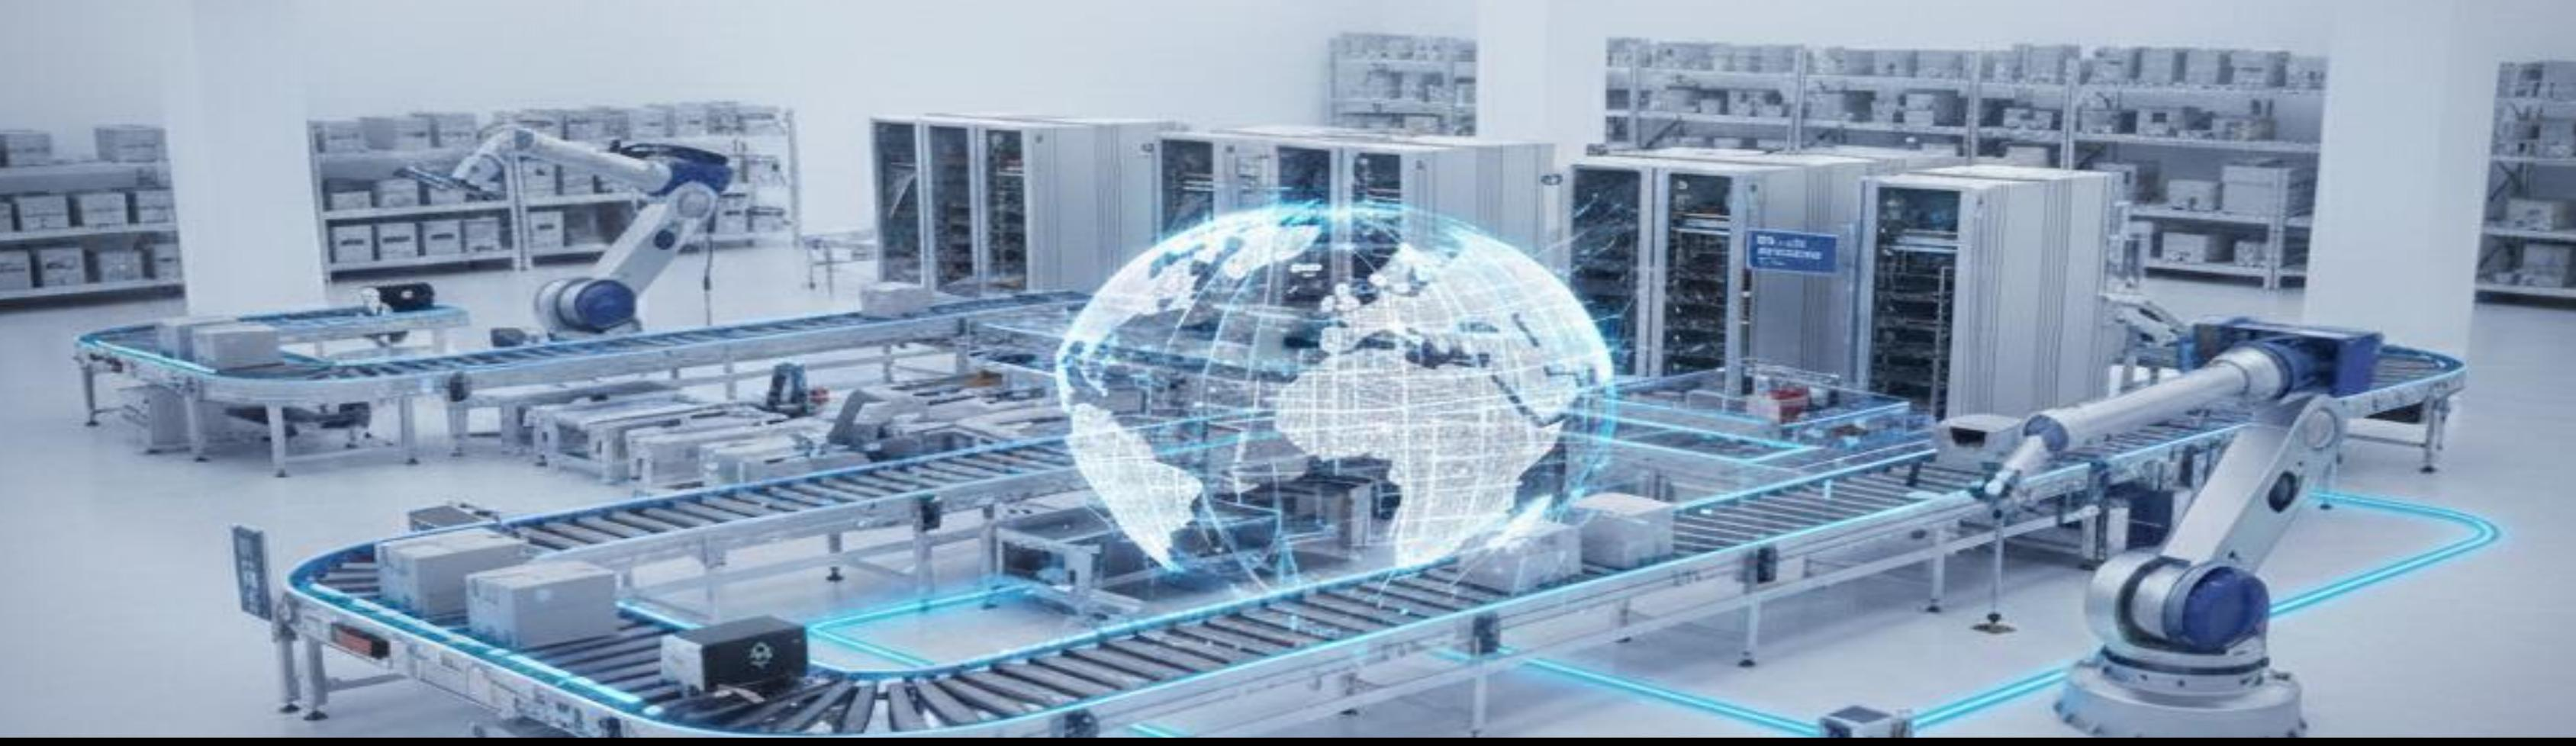

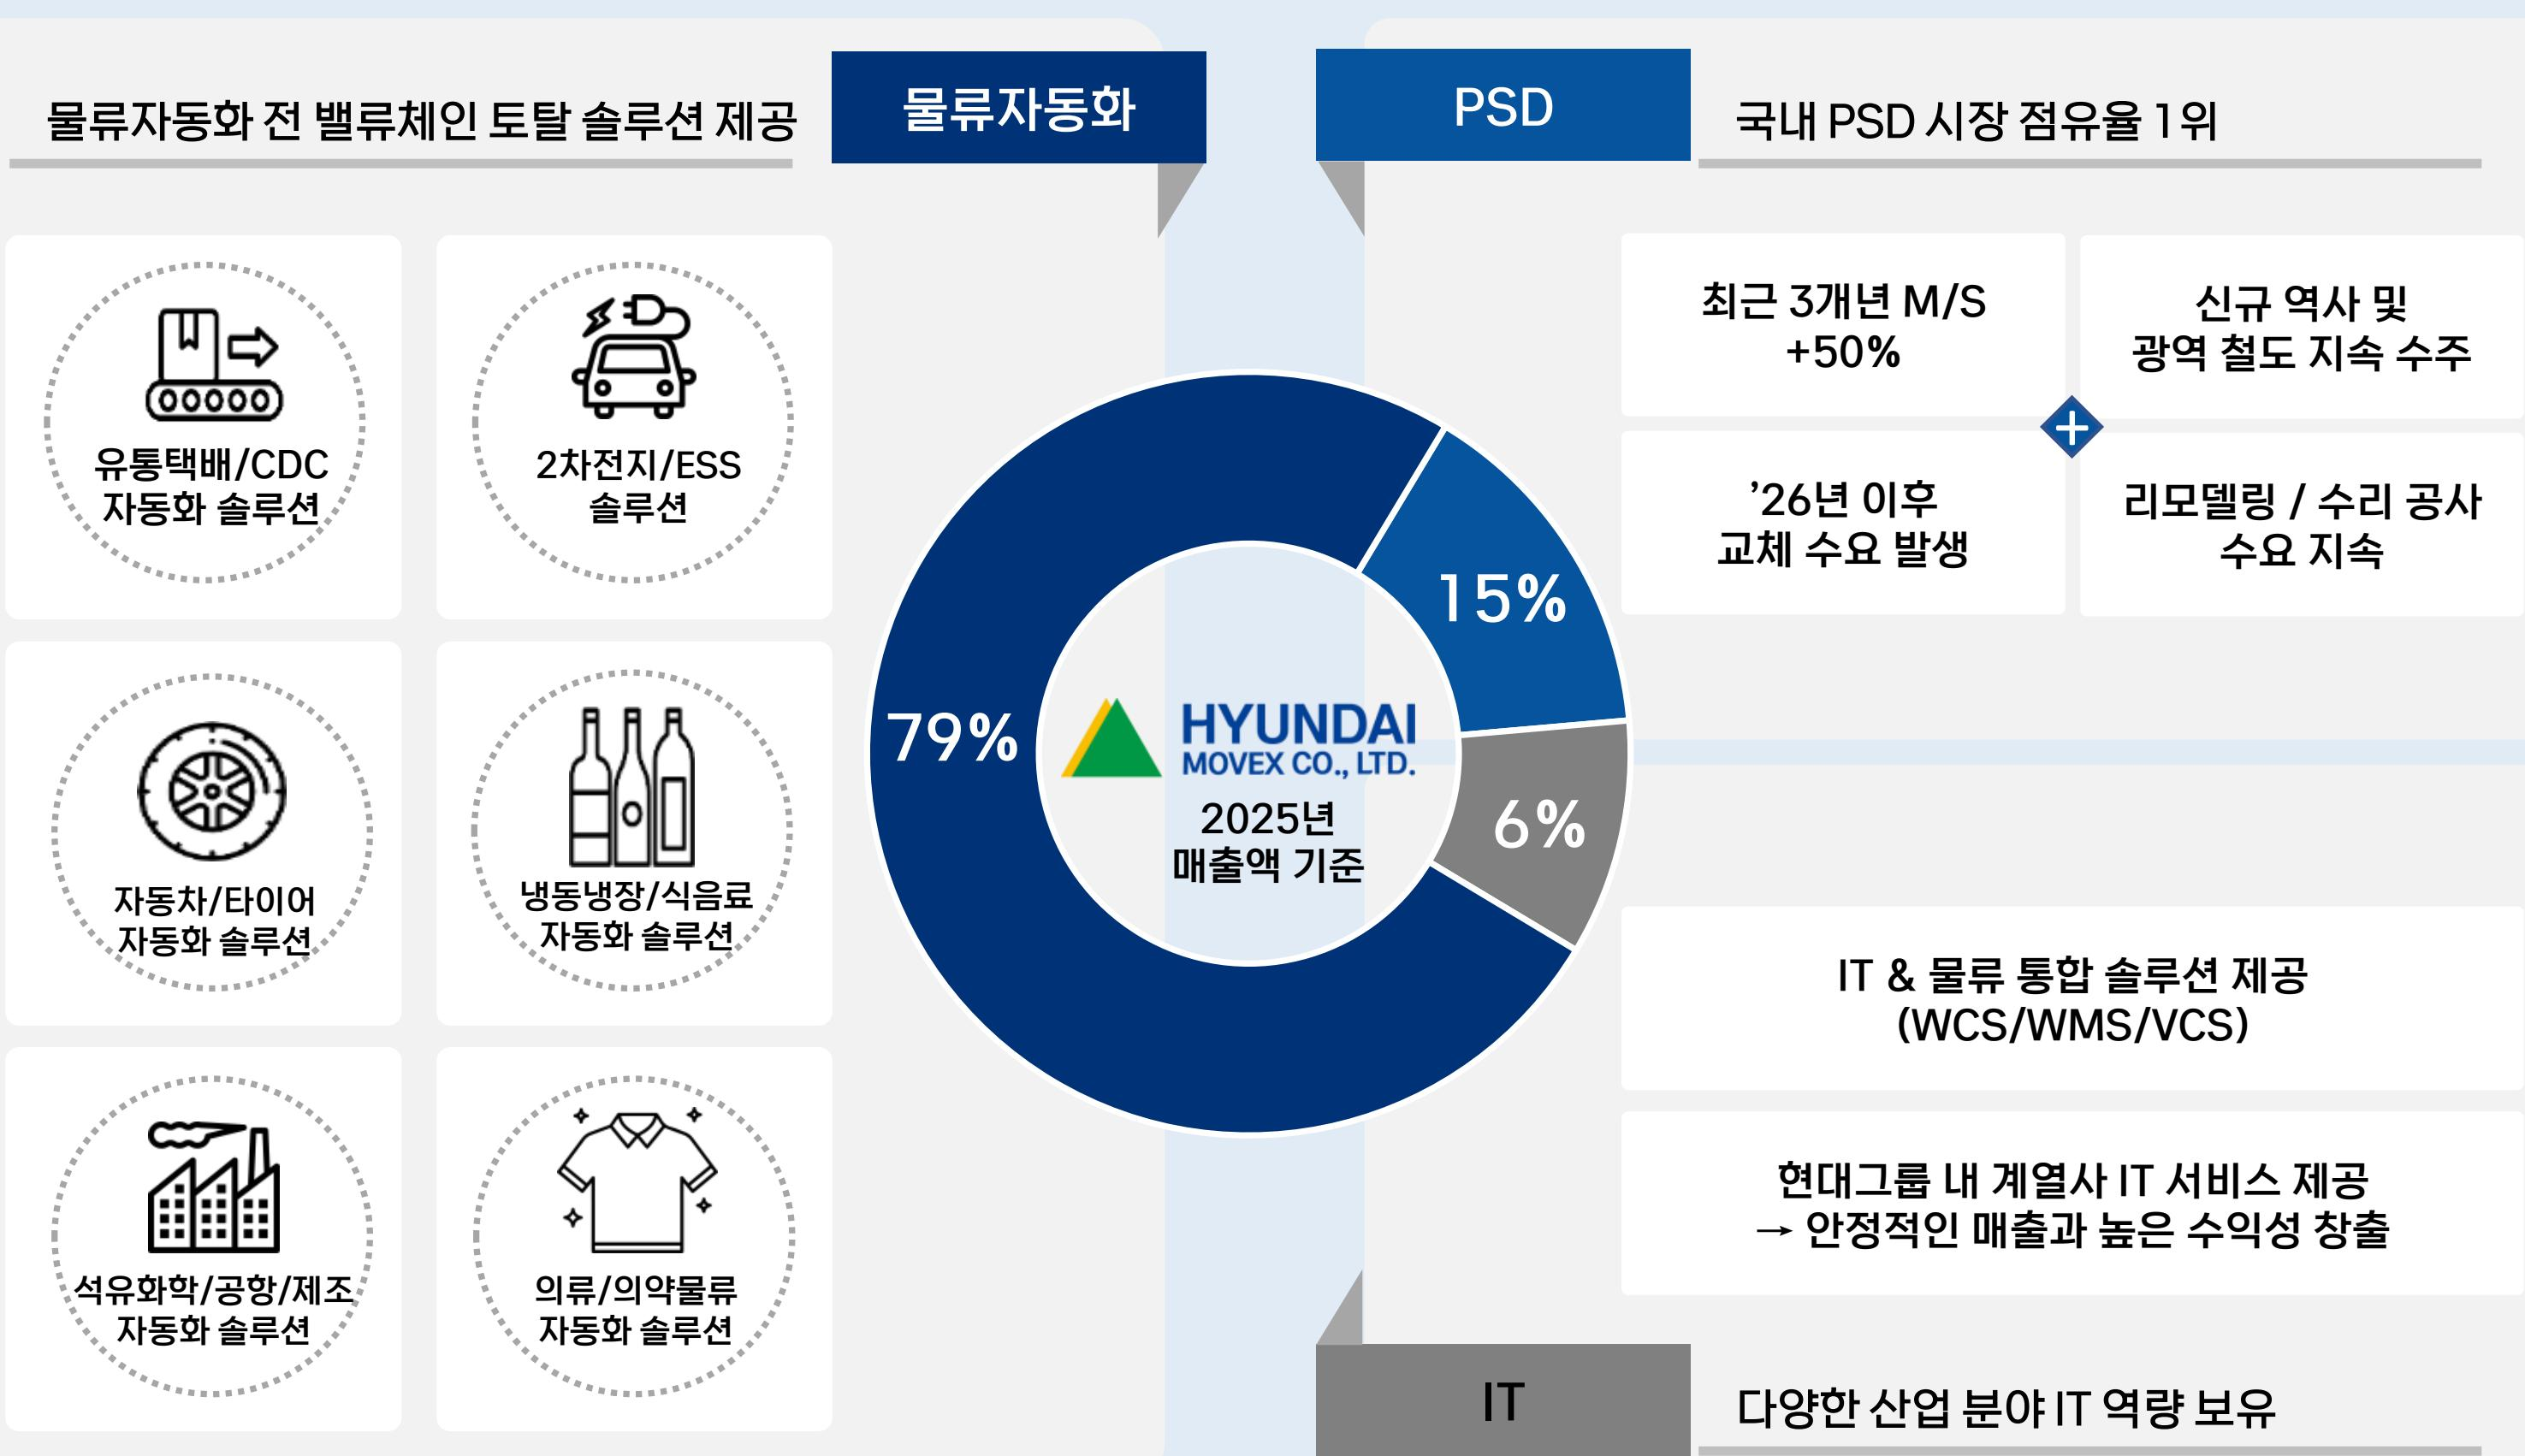

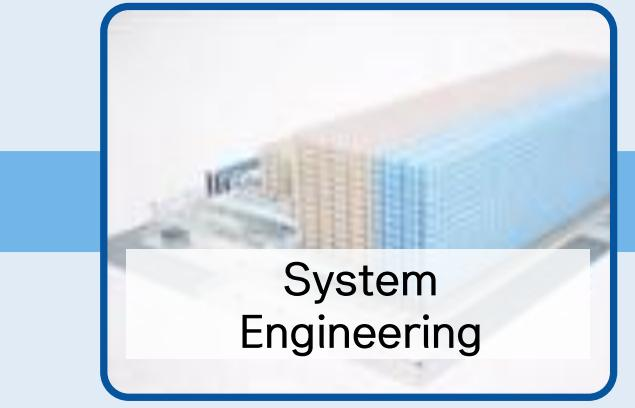

In [75]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.
import IPython.display as display
import IPython.display as Image

# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.

for i, (img, summary) in enumerate(zip(image_files[:3], image_summaries[:3])):
    display.display(display.HTML(f"<hr><h3>Image {i+1}</h3>"))
    display.display(Image.Image(data=img, width=450))
    display.display(display.HTML(f"<p><strong>Summary:</strong> {summary}</p>"))

**🗒️ 정리해 보기 (더블클릭해서 편집)**

- 내 요약의 수준 (나쁨 / 보통 / 좋음):
- 그렇게 판단한 이유:
- 개선하려면 프롬프트에 무엇을 추가할까:

> 💡 품질이 나쁘면 프롬프트에 **"축 이름, 수치 범위, 추세를 반드시 포함하세요"** 같은 지시를 추가해 보세요.

---
# Part 4. 마무리

## 10. 토큰 사용량 측정

### 📖 개념
- `tiktoken` = OpenAI 모델이 글자를 자르는 방식(토큰화)을 로컬에서 그대로 재현하는 도구
- **실제 비용 = 토큰 수 × 단가** (단가는 OpenAI 공식 가격 페이지에서 확인)
- 이미지 토큰은 해상도에 따라 달라 이 계산에 포함되지 않습니다.

In [76]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.
import tiktoken
enc = tiktoken.encoding_for_model("gpt-4o-mini")

# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens
input_tokens = sum(len(enc.encode(text)) for text in texts_2k_token)

# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens
output_tokens = sum(len(enc.encode(summary)) for summary in text_summaries)

# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.
print(f"입력 토큰: {input_tokens:,}")
print(f"출력 토큰: {output_tokens:,}")
print(f"합계 토큰: {input_tokens + output_tokens:,}")
print(f"요약된 이미지 수: {len(image_summaries)}")



입력 토큰: 3,349
출력 토큰: 514
합계 토큰: 3,863
요약된 이미지 수: 45


## 11. 저장

### 📖 개념
요약 생성에도 **API 비용과 시간**이 듭니다. 다음 시간(벡터 저장소 구축)에서 바로 불러 쓰도록 저장합니다.

In [77]:
# ⌨️ 11-1. PROJECT_ROOT / "data" / "processed" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list
with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump({
        "text_summaries": text_summaries,
        "table_summaries": table_summaries,
        "image_summaries": image_summaries,
        "img_base64_list": img_base64_list
    }, f)

# ⌨️ 11-3. 저장 경로를 출력합니다.

print(f"요약 데이터가 {output_dir / 'summaries.pkl'}에 저장되었습니다.")


요약 데이터가 c:\workspace\Multimodal\1105_multimodal\data\processed\summaries.pkl에 저장되었습니다.


---

## ✅ 오늘의 체크포인트

- [✅] `text_summaries[0]`에 한국어 요약문이 출력된다
- [✅] `image_summaries[0]`에 그림을 설명하는 한국어 문장이 출력된다
- [✅] 그림과 요약문을 나란히 놓고 **육안으로 검증**했다
- [✅] `table_summaries`가 비어도 그 이유를 설명할 수 있다
- [✅] `data/processed/summaries.pkl` 파일이 생성되었다

## 💬 생각해 볼 질문 (더블클릭해서 편집)

**Q1. 이미지를 왜 굳이 텍스트로 요약할까요? 이미지 그대로 검색하면 안 되나요?**

답: llm은 base64기반의 텍스트만 읽을 수 있기 때문!

**Q2. 요약문만 저장하고 원본은 버리면 어떤 문제가 생길까요?**

답: 해봤는데 문제 없었습니다. pkl만 있다면!

**Q3. `max_concurrency`를 100으로 올리면 어떤 일이 벌어질까요?**

답: 동시에 너무 많은 작업을 하게되어 문제가 생깁니다. 

## 🛠️ 자주 나는 에러

| 증상 | 원인 | 해결 |
| --- | --- | --- |
| `AuthenticationError` | `.env` 키 오타 / `load_dotenv()` 누락 | 키 앞뒤 공백·따옴표 제거 |
| `404 model not found` | 지원 종료된 모델명 사용 | `gpt-4o-mini` 사용 |
| `RateLimitError` | 동시 요청 과다 | `max_concurrency`를 5 → 2로 낮추기 |
| `FileNotFoundError: extracted.pkl` | 지난 시간 저장 셀 미실행 | 지난 노트북 마지막 셀 재실행 |
| `IndexError: list index out of range` | `figures/`에 이미지가 없음 | 1번 셀의 `figures_dir` 경로 확인 |
| 요약이 영어로 나옴 | 프롬프트에 한국어 지시 누락 | 프롬프트 마지막 줄 확인 |
| `NameError` | 앞 셀을 안 돌림 | 위에서부터 순서대로 재실행 |

> 그래도 안 되면 **커널 재시작 후 위에서부터 전체 재실행**하세요.

## ⏭️ 다음 시간 예고
오늘 만든 요약문을 **임베딩해 벡터 저장소(Chroma)에 넣고**, 요약으로 검색해 **원본**을 돌려주는 **멀티 벡터 검색기**를 만듭니다.